# Assignment 2 — Part 1-3: handcrafted encodings (BoVW / VLAD / Fisher Vector)
**Protocol.** The provided `val` split is the held-out **test** set (used once for reporting). Every choice
(C, normalisation, spatial vs global) is made on a stratified `dev` split carved from `train` (`src/eval.py`).
Seeds are fixed. One-vs-rest: positives = category, negatives = `background` (same as the starter).

In [1]:
import sys, platform, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn
warnings.filterwarnings("ignore")
from src import utils, encoders, features, eval as ev
from src.visualization import displayRankedImageList, displayPrecisionRecallCurve, RelevantVisualWordsDisplay

ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / "data" / "images").exists())
DATA = str(ROOT / "data"); RES = ROOT / "code" / "results"; RES.mkdir(exist_ok=True, parents=True)
SEEDS = (0, 1, 2)
pd.set_option("display.width", 200)
print(f"python {platform.python_version()} | numpy {np.__version__} | sklearn {sklearn.__version__} | {platform.platform()}")
print("cyvlfeat available:", features.dsift is not None)

python 3.11.18 | numpy 2.4.6 | sklearn 1.9.1 | Linux-6.18.44-fc-v236-x86_64-with-glibc2.39
cyvlfeat available: True


# Stage A — Data

,train,test_val
category,,
background,1019,1077
motorbike,120,125
aeroplane,112,126
person,1025,983
car,376,337
horse,139,148


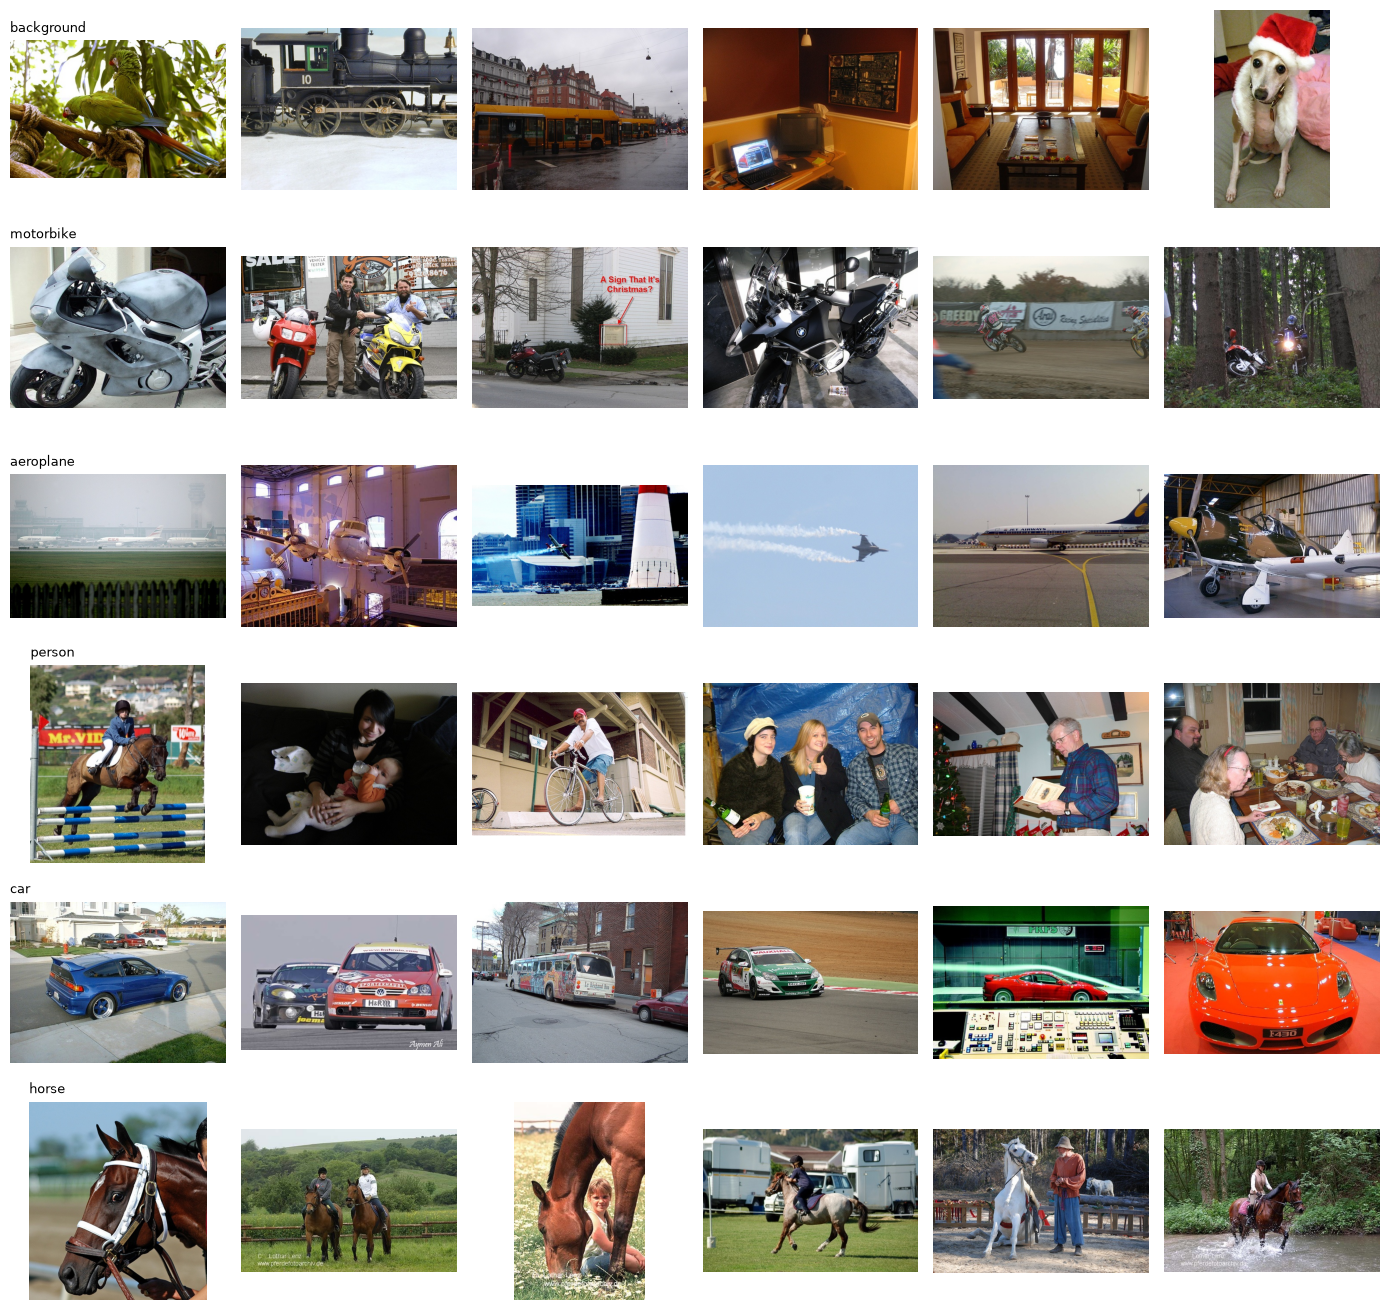

In [2]:
rows = []
for cat in ["background"] + ev.CATEGORIES:
    n = {s: len(np.load(f"{DATA}/encodings/bovw_K512_C0/{cat}_{s}.npz")["file_names"]) for s in ("train", "val")}
    rows.append(dict(category=cat, train=n["train"], test_val=n["val"]))
display(pd.DataFrame(rows).set_index("category"))

# inspect examples: positives and backgrounds
fig, ax = plt.subplots(len(ev.CATEGORIES) + 1, 6, figsize=(14, 2.2 * (len(ev.CATEGORIES) + 1)))
for r, cat in enumerate(["background"] + ev.CATEGORIES):
    names = np.load(f"{DATA}/encodings/bovw_K512_C0/{cat}_train.npz")["file_names"]
    for c, nm in enumerate(np.random.default_rng(0).choice(names, 6, replace=False)):
        ax[r, c].imshow(plt.imread(f"{DATA}/images/{nm}.jpg")); ax[r, c].axis("off")
    ax[r, 0].set_title(cat, loc="left", fontsize=9)
plt.tight_layout(); plt.show()

# Stage B/C — Motorbike classifier (BoVW K=512, 2x2 tiles) + retrieval on test
C is selected on `dev`; the final model is refit on all of `train` and ranked on test once.

C chosen on dev: 10.0


,C,train_ap,dev_ap
0,0.1,0.900453,0.441962
1,1.0,0.895839,0.491696
2,10.0,0.948216,0.528400
3,100.0,0.999107,0.511789
4,1000.0,0.999107,0.511789


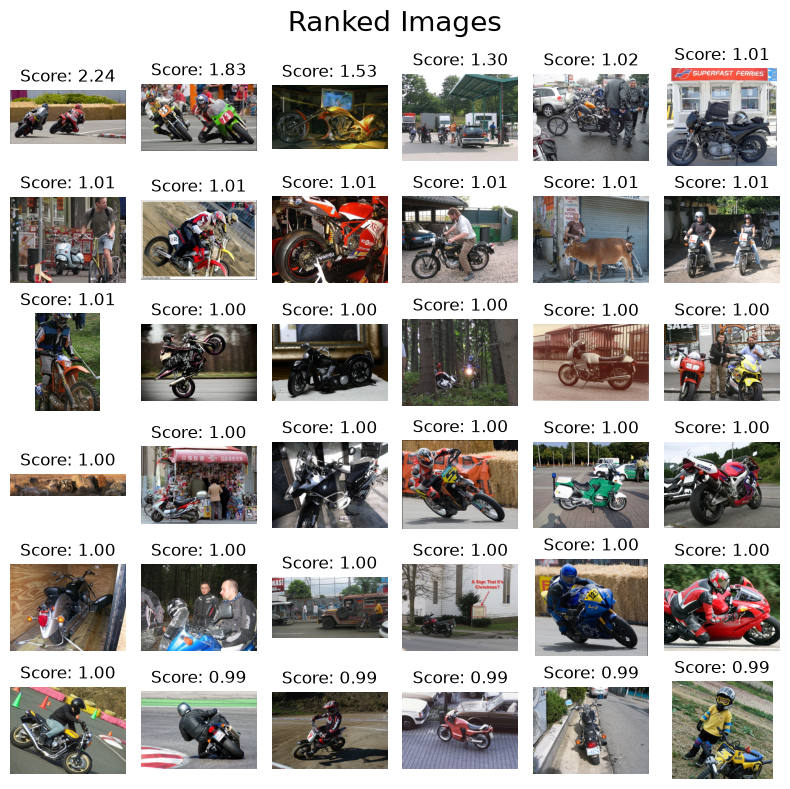

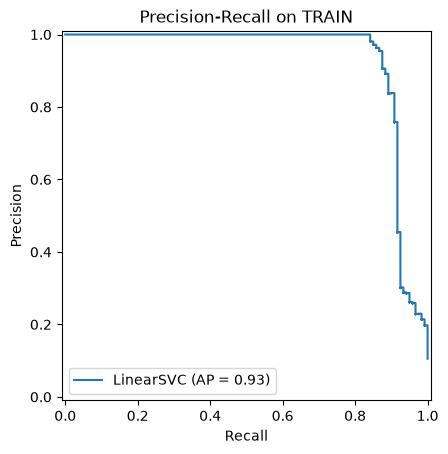

Correctly retrieved in the top 36: 29


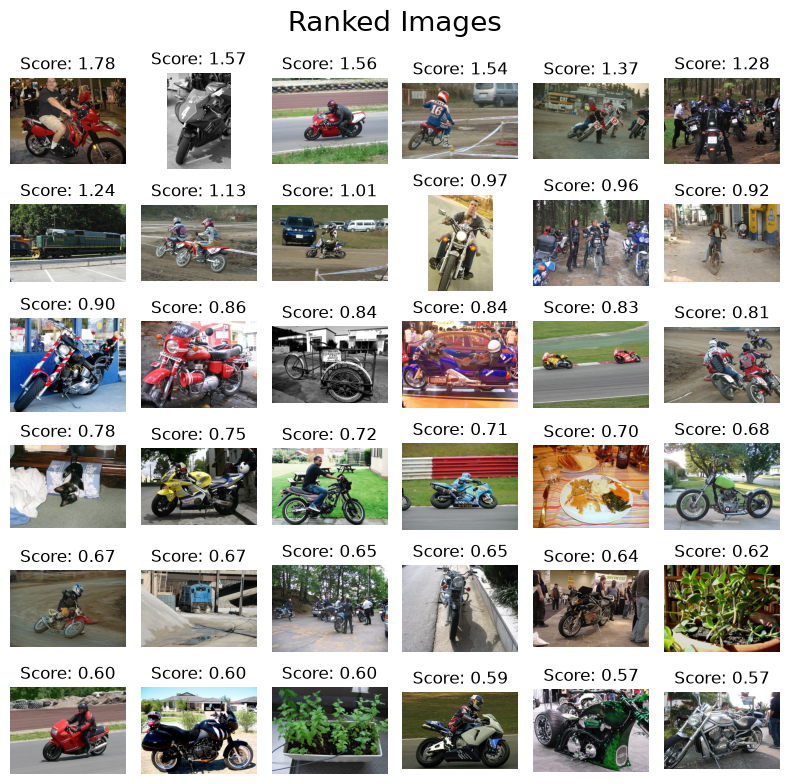

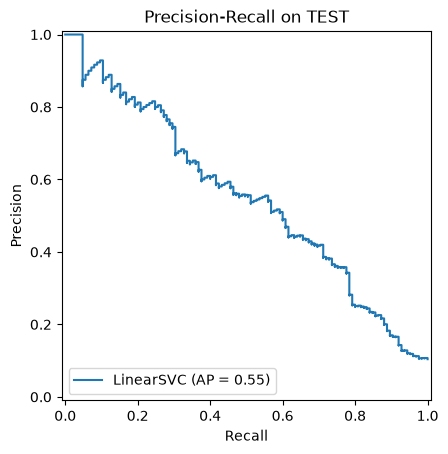

train AP 0.9319 | test AP 0.5515 | P@5/10/20: [1.0, 0.9, 0.85]


In [3]:
encoding, category = "bovw_K512_C0", "motorbike"
d = ev.load(encoding, category, DATA)
(Xtr, ytr, ntr), (Xte, yte, nte) = d["train"], d["test"]
Xtr, Xte = ev.l2(Xtr), ev.l2(Xte)
(Xa, ya, _), (Xd, yd, _) = ev.train_dev_split(Xtr, ytr, ntr)
C, sel = ev.select_C(Xa, ya, Xd, yd)
print("C chosen on dev:", C); display(sel)
W, b, t = ev.fit(Xtr, ytr, C=C)

tr_scores = ev.score(W, b, Xtr)
displayRankedImageList(tr_scores, [f"{DATA}/images/{n}.jpg" for n in ntr], uniform=False, figzize=(8, 8))
_ = displayPrecisionRecallCurve(ytr, tr_scores, title="Precision-Recall on TRAIN")

te_scores = ev.score(W, b, Xte)
print("Correctly retrieved in the top 36:", int((yte[np.argsort(-te_scores)[:36]] > 0).sum()))
displayRankedImageList(te_scores, [f"{DATA}/images/{n}.jpg" for n in nte], uniform=False, figzize=(8, 8))
*_, ap_te = displayPrecisionRecallCurve(yte, te_scores, title="Precision-Recall on TEST")
print(f"train AP {ev.ap(ytr, tr_scores):.4f} | test AP {ap_te:.4f} | P@5/10/20:",
      [round(ev.precision_at_k(yte, te_scores, k), 2) for k in (5, 10, 20)])

Number of keypoints: 41771 Descriptor dimension: 128


top-scored test image: 000374 | visual words with occurrences: 512


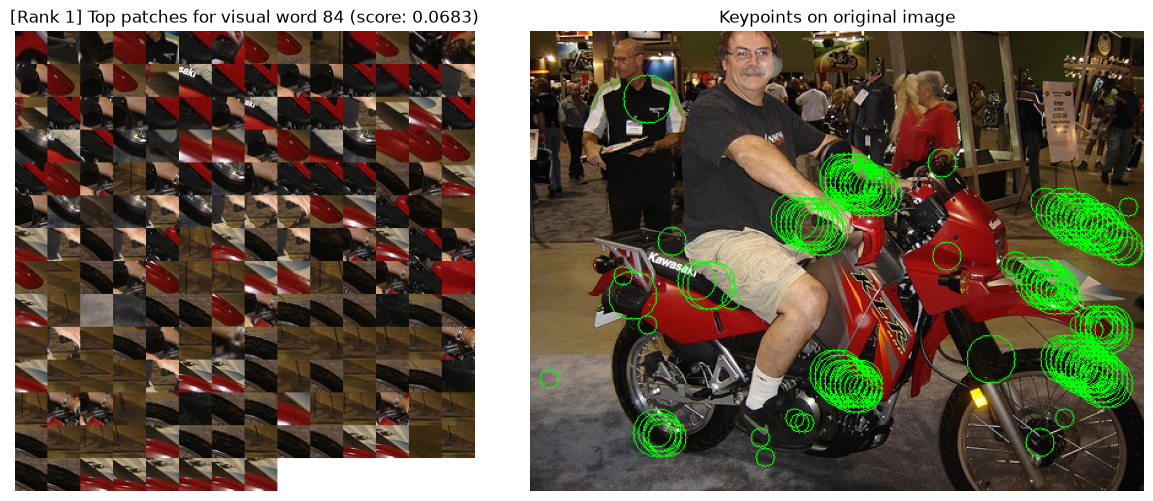

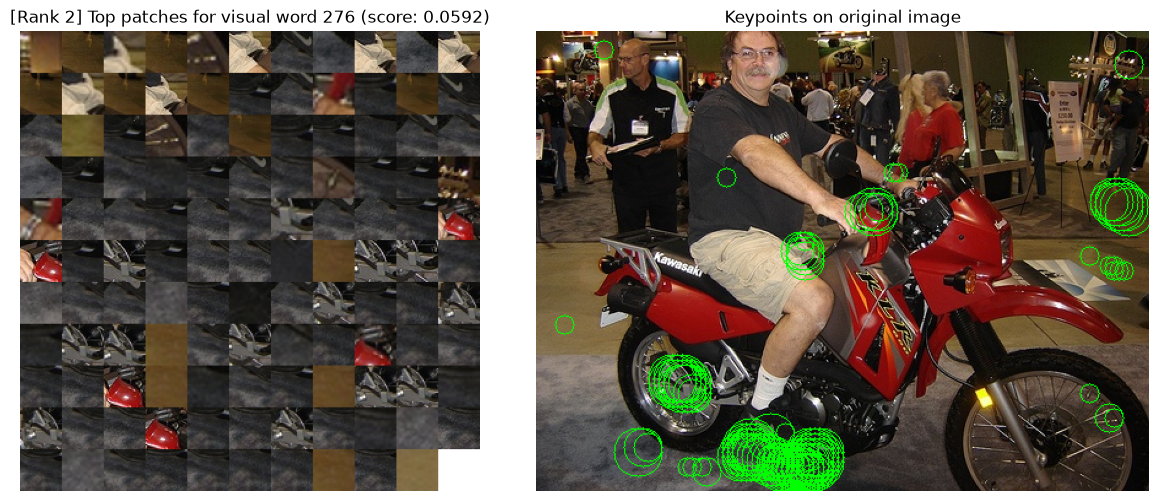

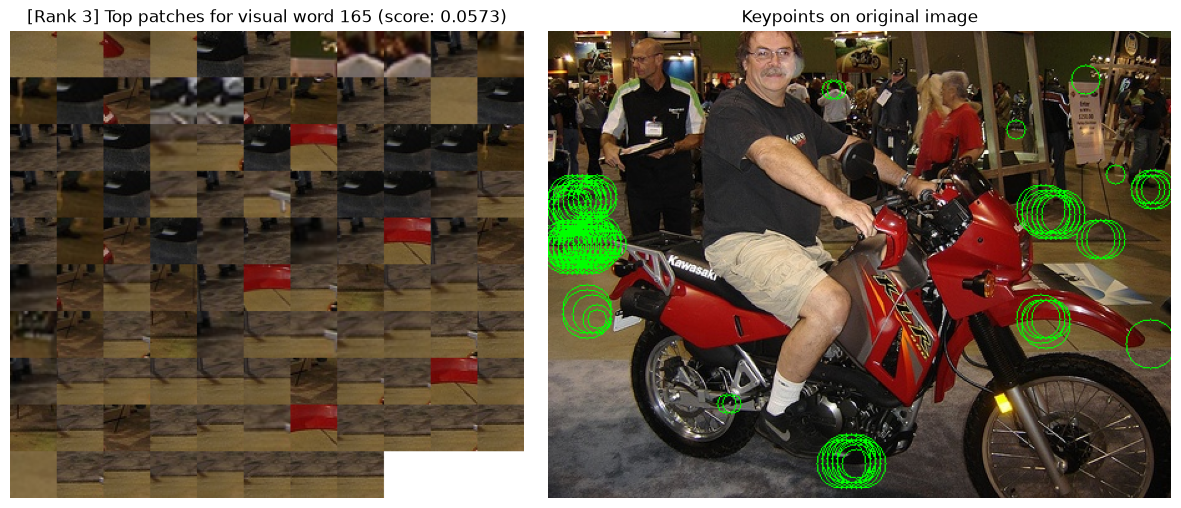

In [4]:
# Relevant visual words (Stage B): static version, works headless. Needs cyvlfeat (dense SIFT).
if features.dsift is None:
    print("cyvlfeat not installed: skipping RelevantVisualWordsDisplay (run this cell on a machine with cyvlfeat).")
else:
    enc = encoders.ImageEncoder(f"{DATA}/encoders/{encoding}.npz")
    nm = nte[np.argmax(te_scores)]
    img = encoders.standarizeImage(f"{DATA}/images/{nm}.jpg")
    rvw = RelevantVisualWordsDisplay(img, W, enc)
    print("top-scored test image:", nm, "| visual words with occurrences:", len(rvw))
    for rank in range(3):
        rvw.plot(rank, figsize=(12, 5))


**Check — bias is irrelevant to the ranking.** Adding a constant `b` to every score does not change `argsort`.

In [5]:
assert (np.argsort(-te_scores) == np.argsort(-(te_scores - b))).all()
print("ranking identical with and without bias; AP", ev.ap(yte, te_scores - b), "==", ev.ap(yte, te_scores))

ranking identical with and without bias; AP 0.5514750937878509 == 0.5514750937878509


# Stage D — All categories (BoVW K=512, L2, spatial 2x2, C on dev)

In [6]:
res = pd.DataFrame([ev.run("bovw_K512_C0", c, norm="l2", root=DATA) for c in ev.CATEGORIES])
d_ = res[["category", "n_train", "dev_ap", "test_ap", "C", "precision", "recall"]].round(3)
display(d_); print("mAP (test):", round(res.test_ap.mean(), 4))
stats = {c: ev.load("bovw_K512_C0", c, DATA)["train"][1] for c in ev.CATEGORIES}
print("positives in train:", {c: int((y > 0).sum()) for c, y in stats.items()})
d_.to_csv(RES / "part1_stageD.csv", index=False)

,category,n_train,dev_ap,test_ap,C,precision,recall
0,motorbike,1139,0.526,0.550,10.0,0.639,0.368
1,aeroplane,1131,0.544,0.524,10.0,0.600,0.095
2,person,2044,0.700,0.701,10.0,0.676,0.591
3,car,1395,0.708,0.679,1.0,0.761,0.368
4,horse,1158,0.689,0.567,10.0,0.694,0.338


mAP (test): 0.6043


positives in train: {'motorbike': 120, 'aeroplane': 112, 'person': 1025, 'car': 376, 'horse': 139}


# Stage E/F — Normalisation, spatial information and Hellinger map
Rule: configuration is **chosen by mean dev AP over the 5 categories**; test AP is only reported for it.
`hellinger` = sqrt(L1(h)) (already unit L2 norm -> sqrt *then* L2 equals L1 *then* sqrt).

In [7]:
grid = [dict(norm=n, spatial=s) for n in ("none", "l1", "l2", "hellinger") for s in (True, False)]
rows = [ev.run("bovw_K512_C0", c, root=DATA, **g) for g in grid for c in ev.CATEGORIES]
E = pd.DataFrame(rows)
summ = E.groupby(["norm", "spatial"])[["dev_ap", "test_ap"]].mean().rename(columns={"dev_ap": "mean_dev_AP", "test_ap": "mAP_test"})
display(summ.round(4))
best = summ.mean_dev_AP.idxmax(); print("selected on dev:", best, "-> test mAP", round(summ.loc[best, "mAP_test"], 4))
display(E.pivot_table(index=["norm", "spatial"], columns="category", values="test_ap").round(3))
E.to_csv(RES / "part1_stageEF.csv", index=False)

mean_dev_AP  mAP_test
norm      spatial                       
hellinger False         0.7199    0.6698
          True          0.7488    0.7163
l1        False         0.6489    0.6091
          True          0.6975    0.5992
l2        False         0.6239    0.5897
          True          0.6335    0.6043
none      False         0.5183    0.5410
          True          0.6202    0.5927

selected on dev: ('hellinger', np.True_) -> test mAP 0.7163


category           aeroplane    car  horse  motorbike  person
norm      spatial                                            
hellinger False        0.648  0.749  0.669      0.520   0.762
          True         0.717  0.747  0.712      0.631   0.774
l1        False        0.711  0.668  0.505      0.457   0.705
          True         0.598  0.668  0.594      0.417   0.720
l2        False        0.541  0.659  0.579      0.484   0.685
          True         0.524  0.679  0.567      0.550   0.701
none      False        0.575  0.606  0.465      0.446   0.613
          True         0.633  0.631  0.537      0.514   0.648

In [8]:
# Self-similarity of L2-normalised histograms: K(h,h)=1 >= K(h,h') (Cauchy-Schwarz)
H = ev.load("bovw_K512_C0", "motorbike", DATA)["train"][0][:200]
for name in ("none", "l1", "l2"):
    Hn = ev.NORMS[name](H); G = Hn @ Hn.T
    off = G[~np.eye(len(G), dtype=bool)]
    print(f"{name:5s} K(h,h): mean {np.diag(G).mean():.4g} | K(h,h') mean {off.mean():.4g} max {off.max():.4g}")

none  K(h,h): mean 1.96e+07 | K(h,h') mean 5.706e+06 max 1.58e+08
l1    K(h,h): mean 0.01299 | K(h,h') mean 0.003726 max 0.1182
l2    K(h,h): mean 1 | K(h,h') mean 0.3217 max 0.9796


# Stage G — Number of training images (linear/L2 vs Hellinger), 5 seeds

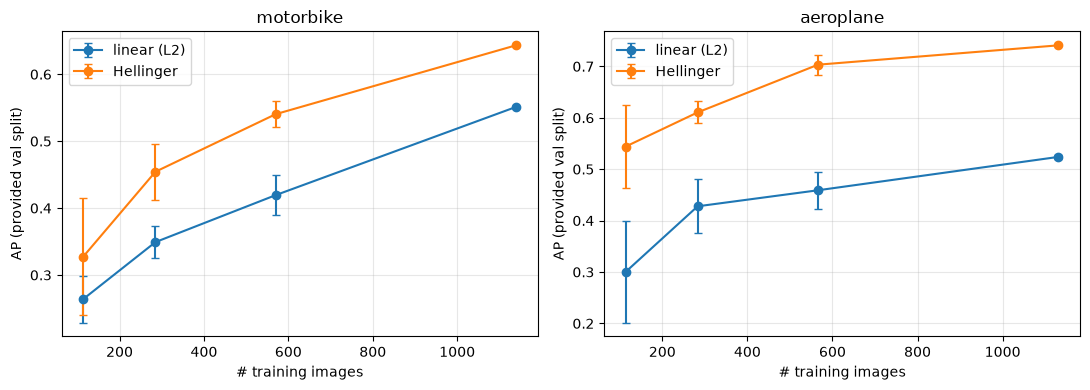

,category,norm,fraction,n_train,ap,sd
0,aeroplane,hellinger,0.10,114.0,0.544,0.081
1,aeroplane,hellinger,0.25,283.0,0.610,0.021
2,aeroplane,hellinger,0.50,566.0,0.703,0.019
3,aeroplane,hellinger,1.00,1131.0,0.741,0.000
4,aeroplane,l2,0.10,114.0,0.300,0.099
5,aeroplane,l2,0.25,283.0,0.428,0.053
6,aeroplane,l2,0.50,566.0,0.459,0.036
7,aeroplane,l2,1.00,1131.0,0.524,0.003
8,motorbike,hellinger,0.10,114.0,0.327,0.087
9,motorbike,hellinger,0.25,285.0,0.454,0.042


In [9]:
fr = (0.1, 0.25, 0.5, 1.0)
G = pd.DataFrame([ev.run("bovw_K512_C0", c, norm=n, fraction=f, seed=s, C=10, root=DATA)
                  for c in ("motorbike", "aeroplane") for n in ("l2", "hellinger") for f in fr for s in range(5)])
agg = G.groupby(["category", "norm", "fraction"]).agg(n_train=("n_train", "mean"), ap=("test_ap", "mean"), sd=("test_ap", "std")).reset_index()
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, cat in zip(axs, ("motorbike", "aeroplane")):
    for n, m in (("l2", "linear (L2)"), ("hellinger", "Hellinger")):
        a = agg[(agg.category == cat) & (agg.norm == n)]
        ax.errorbar(a.n_train, a.ap, a.sd, marker="o", capsize=3, label=m)
    ax.set_title(cat); ax.set_xlabel("# training images"); ax.set_ylabel("AP (provided val split)"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show(); display(agg.round(3)); agg.to_csv(RES / "part1_stageG.csv", index=False)

# Part 2 — BoVW vs VLAD vs Fisher Vector (same splits, same linear SVM)
BoVW -> Hellinger; VLAD / FV -> signed-sqrt + L2 (power normalisation). C by dev AP.
Extraction time is not re-measured here (descriptors are precomputed); train/inference/storage are.

In [10]:
cfgs = [("BoVW K512", "bovw_K512_C0", "hellinger"), ("VLAD K32 PCA80", "vlad_K32_C80", "ssqrt_l2"), ("FV K32 PCA80", "fv_K32_C80", "ssqrt_l2")]
P2 = pd.DataFrame([dict(method=m, **ev.run(e, c, norm=n, root=DATA)) for m, e, n in cfgs for c in ev.CATEGORIES])
tab = P2.pivot_table(index="method", columns="category", values="test_ap")
tab["mAP"] = tab.mean(axis=1)
cost = P2.groupby("method").agg(dim=("dim", "first"), train_s=("train_s", "mean"), infer_ms_per_img=("infer_ms_per_img", "mean"), test_MB=("test_MB", "first"))
part2 = tab.join(cost).loc[[m for m, *_ in cfgs]]
display(part2.round(4)); part2.to_csv(RES / "part2_encodings.csv")

,aeroplane,car,horse,motorbike,person,mAP,dim,train_s,infer_ms_per_img,test_MB
method,,,,,,,,,,
BoVW K512,0.7169,0.7470,0.7118,0.6314,0.7741,0.7163,2048,0.1132,0.0010,9.3906
VLAD K32 PCA80,0.7818,0.8002,0.7435,0.7540,0.8163,0.7791,10240,0.7696,0.0253,46.9531
FV K32 PCA80,0.7760,0.8207,0.7531,0.7921,0.8300,0.7944,20608,1.8992,0.0099,94.4932


# Part 3 (and Part 1 Stage A) — Vocabulary size vs PCA
Vocabularies: K = 32, 64, 256, 1024 trained with `python -m src.run_vocab` (same descriptors sample, same k-means settings as
`src.train`, same 2x2 tiling), plus the provided K = 512. The tiled BoVW dimension is **4K**, so K=32/64 tiled (dim 128/256) are the
"directly small vocabulary" baselines of condition D for PCA 128/256; the global (untiled) histograms are also listed, with dimension K.

PCA is fitted on train only. Vocabularies are fixed (trained once, seed 42): seeds vary only the dev split/C selection, so `mAP_sd` does not
include codebook variance. Recognition: one-vs-background AP/mAP, and 5-way accuracy/macro-F1 on val images with exactly one category.


BoVW encodings found: ['bovw_K32_C0', 'bovw_K64_C0', 'bovw_K256_C0', 'bovw_K512_C0', 'bovw_K1024_C0']


,K,spatial,orig_dim,pca,mAP,dev_mAP,dim,pca_s,train_s,infer_ms,test_MB,dims_removed_%,mAP_sd,acc,macro_f1
0,32,False,32,0,0.5086,0.5509,32,0.0000,0.0049,0.0000,0.1467,0.0000,0.0155,0.6404,0.3740
1,32,True,128,0,0.5787,0.5934,128,0.0000,0.0128,0.0000,0.5869,0.0000,0.0071,0.6902,0.4426
2,32,True,128,64,0.5621,0.5780,64,0.0110,0.0057,0.0000,0.2935,50.0000,0.0038,0.7289,0.4402
3,64,False,64,0,0.5431,0.5944,64,0.0000,0.0089,0.0000,0.2935,0.0000,0.0157,0.5223,0.2927
4,64,True,256,0,0.6189,0.6346,256,0.0000,0.0206,0.0001,1.1738,0.0000,0.0064,0.7353,0.4447
5,64,True,256,64,0.5866,0.6300,64,0.0233,0.0059,0.0000,0.2935,75.0000,0.0097,0.6081,0.3951
6,64,True,256,128,0.6213,0.6340,128,0.0418,0.0109,0.0000,0.5869,50.0000,0.0032,0.7335,0.4493
7,256,False,256,0,0.6217,0.6539,256,0.0000,0.0260,0.0001,1.1738,0.0000,0.0171,0.7192,0.4348
8,256,False,256,64,0.6071,0.6318,64,0.0235,0.0074,0.0000,0.2935,75.0000,0.0076,0.6645,0.4447
9,256,False,256,128,0.6213,0.6522,128,0.0416,0.0125,0.0000,0.5869,50.0000,0.0113,0.7073,0.4142


category,aeroplane,car,horse,motorbike,person,mAP
K,,,,,,
32,0.637,0.642,0.535,0.434,0.646,0.579
64,0.660,0.684,0.613,0.434,0.703,0.619
256,0.701,0.731,0.670,0.610,0.773,0.697
512,0.724,0.748,0.695,0.632,0.780,0.716
1024,0.723,0.746,0.729,0.684,0.802,0.737


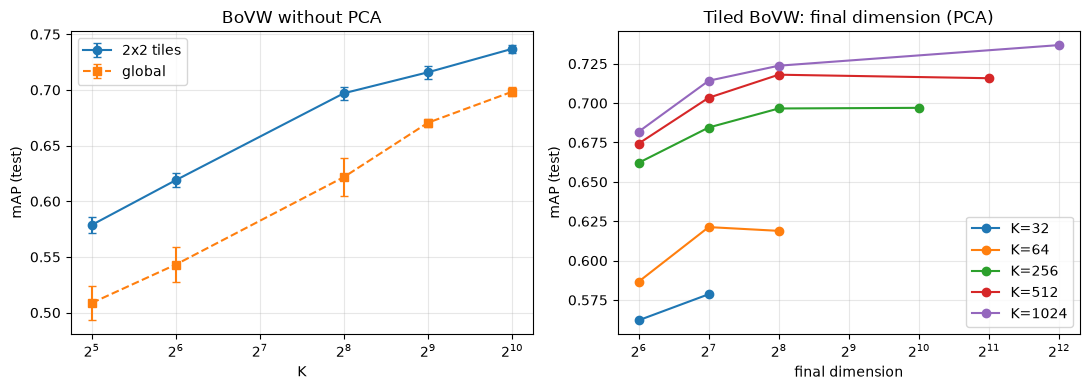

In [11]:
import glob
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, f1_score
bovw_encs = sorted({Path(p).name for p in glob.glob(f"{DATA}/encodings/bovw_K*_C0")}, key=lambda s: int(s.split("_K")[1].split("_")[0]))
print("BoVW encodings found:", bovw_encs)
table = ev.split_table(DATA)

def enc_matrix(e):
    d = {}
    for c in ev.ALL_CATS:
        for sp in ("train", "val"):
            z = np.load(f"{DATA}/encodings/{e}/{c}_{sp}.npz"); d.update(zip(map(str, z["file_names"]), z["histograms"]))
    return np.stack([d[str(n)] for n in table.name.values])

def five_way(F, Cs, pca, seed):
    """5-way accuracy / macro-F1: OvR SVMs (C per class from dev), PCA on train only, val images with one category."""
    F = ev.hellinger(F)
    if pca:
        F = PCA(pca, random_state=seed).fit(F[(table.split == "train").values]).transform(F)
    S, true, _ = ev.ovr_scores(F, table, Cs, norm="none")
    return accuracy_score(true, S.argmax(1)), f1_score(true, S.argmax(1), average="macro")

rows, fw = [], []
for e in bovw_encs:
    K = int(e.split("_K")[1].split("_")[0]); Fm = enc_matrix(e)
    for spatial in (True, False):
        D0 = 4 * K if spatial else K
        for pca in [0] + [k for k in (64, 128, 256) if k < D0]:
            for s in SEEDS:
                r = [dict(K=K, orig_dim=D0, **ev.run(e, c, norm="hellinger", pca=pca, spatial=spatial, seed=s, root=DATA)) for c in ev.CATEGORIES]
                rows += r
                Fx = Fm if spatial else encoders.removeSpatialInformation(Fm)
                a, m = five_way(Fx, {x["category"]: x["C"] for x in r}, pca, s)
                fw.append(dict(encoding=e, spatial=spatial, pca=pca, seed=s, acc=a, macro_f1=m))
P3 = pd.DataFrame(rows); FW = pd.DataFrame(fw)
keys = ["K", "spatial", "orig_dim", "pca"]
agg = (P3.groupby(keys).agg(mAP=("test_ap", "mean"), dev_mAP=("dev_ap", "mean"), dim=("dim", "first"), pca_s=("pca_s", "mean"),
              train_s=("train_s", "mean"), infer_ms=("infer_ms_per_img", "mean"), test_MB=("test_MB", "first")).reset_index())
agg["dims_removed_%"] = np.where(agg.pca > 0, 100 * (1 - agg["dim"] / agg.orig_dim), 0.0)
sd = P3.groupby(["K", "spatial", "pca", "seed"]).test_ap.mean().groupby(["K", "spatial", "pca"]).std().rename("mAP_sd").reset_index()
FW["K"] = FW.encoding.str.extract(r"_K(\d+)_").astype(int)
fwa = FW.groupby(["K", "spatial", "pca"]).agg(acc=("acc", "mean"), macro_f1=("macro_f1", "mean")).reset_index()
agg = agg.merge(sd, on=["K", "spatial", "pca"]).merge(fwa, on=["K", "spatial", "pca"])
display(agg.round(4)); agg.to_csv(RES / "part3_pca_bovw.csv", index=False)

# Stage A: per-class AP vs vocabulary size (no PCA, tiled)
sa = P3[(P3.pca == 0) & P3.spatial].pivot_table(index="K", columns="category", values="test_ap"); sa["mAP"] = sa.mean(axis=1)
display(sa.round(3)); sa.to_csv(RES / "part1_stageA_vocabulary.csv")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for sp, m in ((True, "o-"), (False, "s--")):
    a = agg[(agg.pca == 0) & (agg.spatial == sp)]
    ax[0].errorbar(a.K, a.mAP, a.mAP_sd, fmt=m, capsize=3, label="2x2 tiles" if sp else "global")
ax[0].set_xscale("log", base=2); ax[0].set_xlabel("K"); ax[0].set_ylabel("mAP (test)"); ax[0].legend(); ax[0].grid(alpha=.3); ax[0].set_title("BoVW without PCA")
for K in sorted(agg.K.unique()):
    a = agg[(agg.K == K) & agg.spatial].sort_values("dim")
    ax[1].plot(a["dim"], a.mAP, "o-", label=f"K={K}")
ax[1].set_xscale("log", base=2); ax[1].set_xlabel("final dimension"); ax[1].set_ylabel("mAP (test)"); ax[1].legend(); ax[1].grid(alpha=.3); ax[1].set_title("Tiled BoVW: final dimension (PCA)")
plt.tight_layout(); plt.show()


In [12]:
# PCA on the high-dimensional encodings (VLAD / FV): the effect is larger because raw dim >> K
rows = []
for e, n in (("vlad_K32_C80", "ssqrt_l2"), ("fv_K32_C80", "ssqrt_l2")):
    D0 = np.load(f"{DATA}/encodings/{e}/motorbike_train.npz")["histograms"].shape[1]
    for pca in (0, 128, 256, 512):
        for c in ev.CATEGORIES:
            rows.append(dict(orig_dim=D0, **ev.run(e, c, norm=n, pca=pca, root=DATA)))
P3b = pd.DataFrame(rows)
a3 = P3b.groupby(["encoding", "orig_dim", "pca"]).agg(mAP=("test_ap", "mean"), dim=("dim", "first"), pca_s=("pca_s", "mean"),
        train_s=("train_s", "mean"), infer_ms=("infer_ms_per_img", "mean"), test_MB=("test_MB", "first")).reset_index()
display(a3.round(4)); a3.to_csv(RES / "part3_pca_vlad_fv.csv", index=False)

,encoding,orig_dim,pca,mAP,dim,pca_s,train_s,infer_ms,test_MB
0,fv_K32_C80,20608,0,0.7944,20608,0.0000,1.8699,0.0091,94.4932
1,fv_K32_C80,20608,128,0.7616,128,3.1881,0.0078,0.0001,0.5869
2,fv_K32_C80,20608,256,0.7810,256,3.9568,0.0280,0.0001,1.1738
3,fv_K32_C80,20608,512,0.7868,512,7.2457,0.0228,0.0002,2.3477
4,vlad_K32_C80,10240,0,0.7791,10240,0.0000,0.8480,0.0258,46.9531
5,vlad_K32_C80,10240,128,0.7438,128,0.6993,0.0095,0.0002,0.5869
6,vlad_K32_C80,10240,256,0.7627,256,1.0158,0.0116,0.0005,1.1738
7,vlad_K32_C80,10240,512,0.7739,512,1.9700,0.0219,0.0009,2.3477


## Part 3 — conditions A-D and measured construction costs
Codebook fitting, descriptor and encoding times come from `src.run_vocab` (`results/part3_vocab_costs.json`: 2-core CPU, single thread per
worker, including image loading and preprocessing; excludes model loading).


In [13]:
import json
cost = json.load(open(RES / "part3_vocab_costs.json"))
desc = cost["descriptor_ms_per_img"]
def get(K, sp, pca):
    r = agg[(agg.K == K) & (agg.spatial == sp) & (agg.pca == pca)].iloc[0]
    fit_s = cost.get(f"codebook_fit_s_K{K}", np.nan); enc = cost.get(f"encode_ms_per_img_K{K}", cost.get("timing_encode_ms_per_img_bovw_K512_C0") if K == 512 else np.nan)
    return dict(K=K, tiled=sp, pca=pca, dim=int(r["dim"]), removed_pct=r["dims_removed_%"], mAP=r.mAP, sd=r.mAP_sd, acc=r.acc, macro_f1=r.macro_f1,
                codebook_fit_s=fit_s, encode_ms_per_img=enc, descriptor_ms_per_img=desc, pca_fit_s=r.pca_s, train_s=r.train_s, infer_ms=r.infer_ms, test_MB=r.test_MB)
cond = [("A small", 256, True, 0), ("B large", 1024, True, 0), ("C large+PCA128", 1024, True, 128), ("C large+PCA256", 1024, True, 256),
        ("D compact dim 128 (K=32 tiled)", 32, True, 0), ("D compact dim 256 (K=64 tiled)", 64, True, 0),
        ("D compact dim 256 (K=256 global)", 256, False, 0), ("K=1024 global + PCA256", 1024, False, 256)]
T = pd.DataFrame([dict(condition=n, **get(K, sp, p)) for n, K, sp, p in cond]).set_index("condition")
display(T.round(4)); T.to_csv(RES / "part3_conditions.csv")
# per-class gain of the large vocabulary
display((sa.loc[1024] - sa.loc[256]).round(3).to_frame("AP gain K=1024 vs K=256"))


,K,tiled,pca,dim,removed_pct,mAP,sd,acc,macro_f1,codebook_fit_s,encode_ms_per_img,descriptor_ms_per_img,pca_fit_s,train_s,infer_ms,test_MB
condition,,,,,,,,,,,,,,,,
A small,256,True,0,1024,0.000,0.6970,0.0059,0.7314,0.4772,93.2313,45.9351,128.0002,0.0000,0.0650,0.0005,4.6953
B large,1024,True,0,4096,0.000,0.7368,0.0034,0.7524,0.4817,265.7557,136.6276,128.0002,0.0000,0.2416,0.0019,18.7812
C large+PCA128,1024,True,128,128,96.875,0.7142,0.0028,0.7485,0.4675,265.7557,136.6276,128.0002,0.6119,0.0070,0.0000,0.5869
C large+PCA256,1024,True,256,256,93.750,0.7238,0.0026,0.7234,0.4623,265.7557,136.6276,128.0002,0.7983,0.0143,0.0001,1.1738
D compact dim 128 (K=32 tiled),32,True,0,128,0.000,0.5787,0.0071,0.6902,0.4426,11.1481,19.9574,128.0002,0.0000,0.0128,0.0000,0.5869
D compact dim 256 (K=64 tiled),64,True,0,256,0.000,0.6189,0.0064,0.7353,0.4447,19.9279,22.9228,128.0002,0.0000,0.0206,0.0001,1.1738
D compact dim 256 (K=256 global),256,False,0,256,0.000,0.6217,0.0171,0.7192,0.4348,93.2313,45.9351,128.0002,0.0000,0.0260,0.0001,1.1738
K=1024 global + PCA256,1024,False,256,256,75.000,0.6910,0.0011,0.7295,0.4742,265.7557,136.6276,128.0002,0.2212,0.0169,0.0001,1.1738


,AP gain K=1024 vs K=256
category,
aeroplane,0.023
car,0.015
horse,0.058
motorbike,0.073
person,0.030
mAP,0.040


## Extraction cost of the provided encoders
Measured on 60 random images (2-core CPU). Dense SIFT is shared; the encoding step differs. Feeds the required comparison table.


In [14]:
X = pd.DataFrame([dict(encoder=e, dense_sift_ms=cost["timing_descriptor_ms_per_img"], encode_ms=cost[f"timing_encode_ms_per_img_{e}"],
                       total_ms=cost["timing_descriptor_ms_per_img"] + cost[f"timing_encode_ms_per_img_{e}"])
                  for e in ("bovw_K512_C0", "vlad_K32_C80", "fv_K32_C80")]).set_index("encoder")
display(X.round(1)); X.to_csv(RES / "extraction_times_handcrafted.csv")
tab = pd.read_csv(RES / "final_comparison_table.csv")
for key, e in (("BoVW", "bovw_K512_C0"), ("VLAD", "vlad_K32_C80"), ("Fisher", "fv_K32_C80")):
    tab.loc[tab.Method.str.startswith(key), "Extraction"] = f"{X.loc[e, 'total_ms']:.0f} ms/img (cpu, 2 cores)"
tab.to_csv(RES / "final_comparison_table.csv", index=False); display(tab)


,dense_sift_ms,encode_ms,total_ms
encoder,,,
bovw_K512_C0,107.8,75.4,183.2
vlad_K32_C80,107.8,47.2,154.9
fv_K32_C80,107.8,97.2,204.9


,Method,Supervision,mAP,Dim,Extraction,Inference_ms_per_img,Train_s
0,"BoVW + SVM (K=512, Hellinger)",Task labels,0.716256,2048,"183 ms/img (cpu, 2 cores)",0.000213,0.083254
1,"VLAD + SVM (K=32, PCA80)",Task labels,0.779144,10240,"155 ms/img (cpu, 2 cores)",0.002474,0.437167
2,"Fisher Vector + SVM (K=32, PCA80)",Task labels,0.794371,20608,"205 ms/img (cpu, 2 cores)",0.002123,0.959547
3,ResNet-18 (GAP l2-l4) + SVM,Pretrained + task labels,0.965599,896,3.5 ms/img (mps),0.000344,0.018213
4,ViT-B/32 (CLS) + SVM,Pretrained + task labels,0.974408,768,5.5 ms/img (mps),0.000171,0.019474
5,DINOv2 ViT-S/14 (CLS) + SVM,Self-supervised + task labels,0.987682,384,7.6 ms/img (mps),0.000077,0.007310
6,CLIP ViT-B/32 image emb + SVM (extra),Pretrained + task labels,0.989791,512,6.2 ms/img (mps),0.000101,0.009411
7,CLIP zero-shot (bare class name),Image-text pretraining; no task labels,0.840088,512,6.2 ms/img (mps),0.000000,0.000000
